# 05 · Cerebellum: do the treatments reverse aging?
**Question.** Do dietary restriction (**aDR**) and young plasma (**YMP**) push cerebellar expression back towards the young state? **Input:** RSEM and kallisto results (notebook 01). **Output:** `results/aging_vs_rejuvenation/`. **Kernel:** R (`ir`) · **Time:** ~4 min (the first run downloads the MSigDB gene sets).

The primary method is **RSEM** (STAR alignments); kallisto runs through the same DESeq2 code as a sensitivity check (decision: [docs/pipeline.md](../docs/pipeline.md#choosing-the-counting-method)). Tables cover both, figures show the method in `SHOW`. **Aging signal** = 21 vs 3 months; **reversal** = a treatment moves a gene or pathway opposite to aging.

Sections: 2 aging genes · 3 overlap of treatment and aging DEGs, and direction · 4 per-sample aging-signature score (down = rejuvenation) · 5 pathways reversed? · 6 the paper's named genes · 7 genes shared with aging, and biological themes.

**Caveats:** 3–5 mice per group; treatments at 19 months, aging at 21; aDR female-only, YMP male-only. Scores are z-scored within each treated/control pair, so cohort batch does not enter. P-values are indicative. Terms: [docs/glossary.md](../docs/glossary.md).

## 1 · Setup
`fits` holds, per method, the DESeq2 models (`dds`) and result tables (`res`); SRR21355389 is excluded from aging as in notebook 03.

In [1]:
# counts of both methods -> DESeq2 models and tables; summary of up / down DEGs per comparison
source('../R/helpers.R')
SHOW <- 'RSEM'   # method drawn in the figures and in the single-method tables; every table with a `method` column covers both
samples <- load_samples()
genes <- load_genes()
counts <- list(kallisto = load_txi(rownames(samples))$txi, RSEM = load_rsem(rownames(samples)))
fits <- lapply(counts, \(cn) { d <- run_dds(cn, samples); list(dds = d, res = de_tables(d, genes)) })   # same exclusion of SRR21355389 as notebook 03
bind_rows(lapply(fits, \(f) bind_rows(lapply(f$res, n_deg), .id = 'contrast')), .id = 'method')

method,contrast,up,down
<chr>,<chr>,<int>,<int>
kallisto,aging_18v3,101,25
kallisto,aging_21v3,82,52
kallisto,aDR,64,75
kallisto,YMP,17,24
RSEM,aging_18v3,95,20
RSEM,aging_21v3,74,42
RSEM,aDR,46,72
RSEM,YMP,22,28


## 2 · The aging signature (21 vs 3 months)
The aging DEGs (padj < 0.05), split by direction, are the signature used in analyses 3 and 4.

In [2]:
# numbers of aging-up and aging-down genes per method
sig <- lapply(fits, \(f) { a <- filter(f$res$aging_21v3, padj < 0.05); list(up = a$gene_id[a$log2FoldChange > 0], down = a$gene_id[a$log2FoldChange < 0]) })
tibble(method = names(sig), up = lengths(lapply(sig, `[[`, 'up')), down = lengths(lapply(sig, `[[`, 'down')))

method,up,down
<chr>,<int>,<int>
kallisto,82,52
RSEM,74,42


## 3 · Overlap of treatment DEGs with aging DEGs
`shared` vs `expected_by_chance`; `shared_reversal` = opposite to aging (rejuvenating), `shared_same` = like aging; `fisher_p` = overlap beyond chance; `lfc_spearman_agingDEG` = log2FC correlation with aging among aging DEGs (**negative = reversal**).

In [3]:
# overlap statistics per method and treatment
ov <- bind_rows(lapply(names(fits), \(m) bind_rows(lapply(c('aDR', 'YMP'), \(n)
  overlap_with_aging(fits[[m]]$res$aging_21v3, fits[[m]]$res[[n]]) %>% mutate(intervention = n))) %>% mutate(method = m))) %>% relocate(method, intervention)
ov

method,intervention,genes,aging_DEG,intervention_DEG,shared,expected_by_chance,shared_reversal,shared_same,fisher_p,lfc_spearman_all,lfc_spearman_agingDEG
<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>
kallisto,aDR,16474,124,139,6,1.0,0,6,0.00064,0.140,0.389
kallisto,YMP,19860,132,40,2,0.3,2,0,0.02900,-0.131,-0.476
RSEM,aDR,12959,108,117,5,1.0,0,5,0.00290,0.154,0.438
RSEM,YMP,16603,116,45,2,0.3,2,0,0.03900,-0.143,-0.326


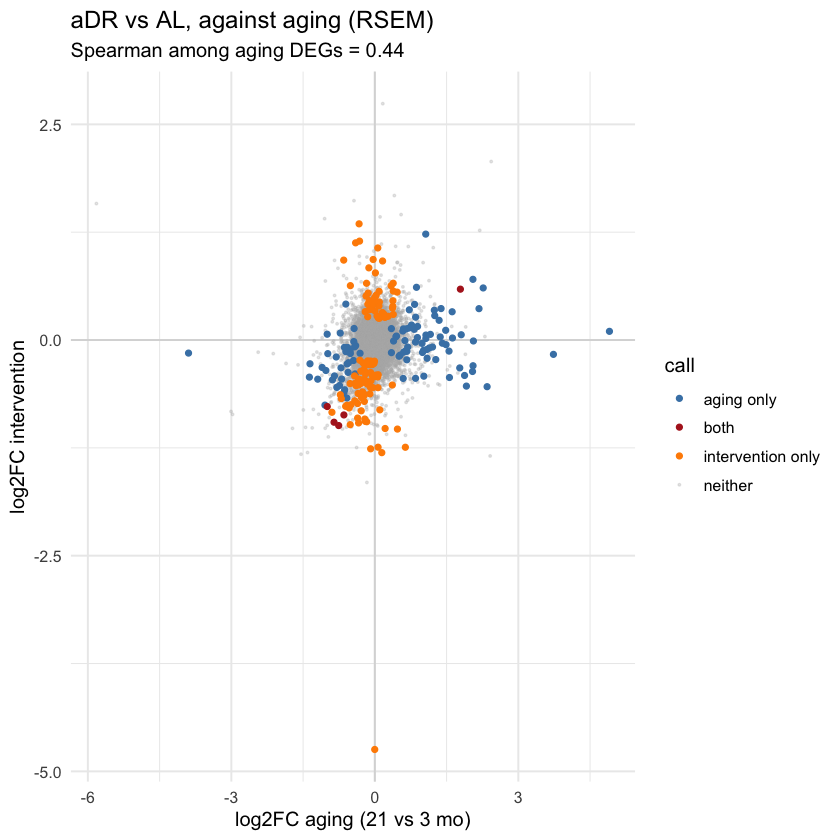

In [4]:
# each dot is a gene: log2FC in aging (x) vs in aDR (y); points on the diagonal move like aging
lfc_vs_aging_plot(fits[[SHOW]]$res$aging_21v3, fits[[SHOW]]$res$aDR, paste0('aDR vs AL, against aging (', SHOW, ')'))

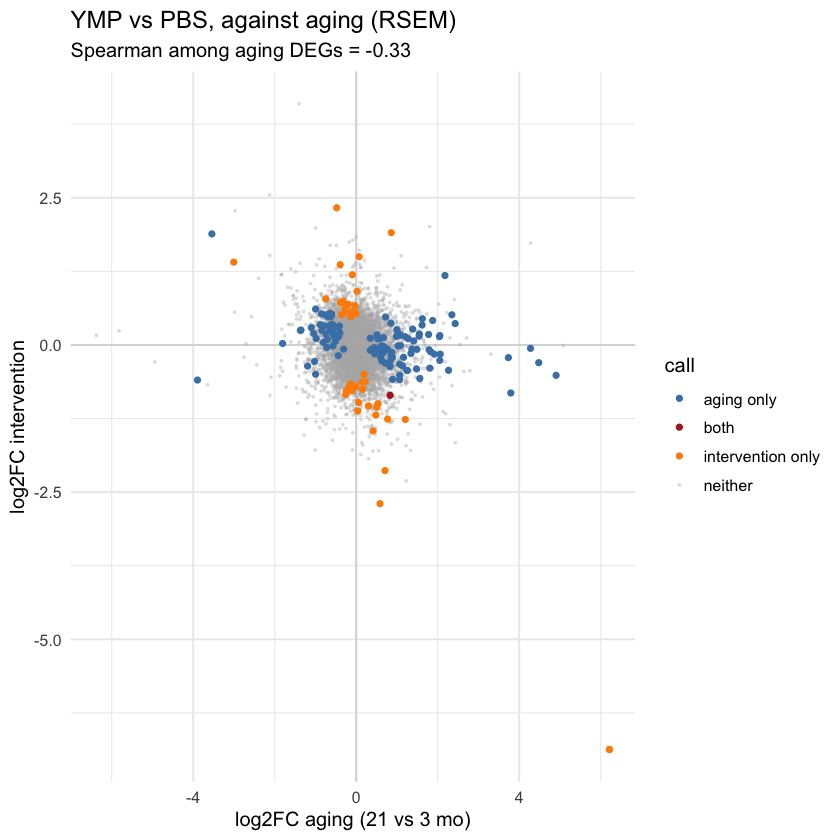

In [5]:
# the same for YMP: points in the upper-left / lower-right quadrants = reversal
lfc_vs_aging_plot(fits[[SHOW]]$res$aging_21v3, fits[[SHOW]]$res$YMP, paste0('YMP vs PBS, against aging (', SHOW, ')'))

## 4 · Aging-signature score per sample
Score = mean z-score of the aging-up genes minus that of the aging-down genes (z-scored within the samples of the same experiment). The *aging* panel is a sanity check (the signature came from these mice); a rejuvenating treatment should **lower** the score relative to its control.

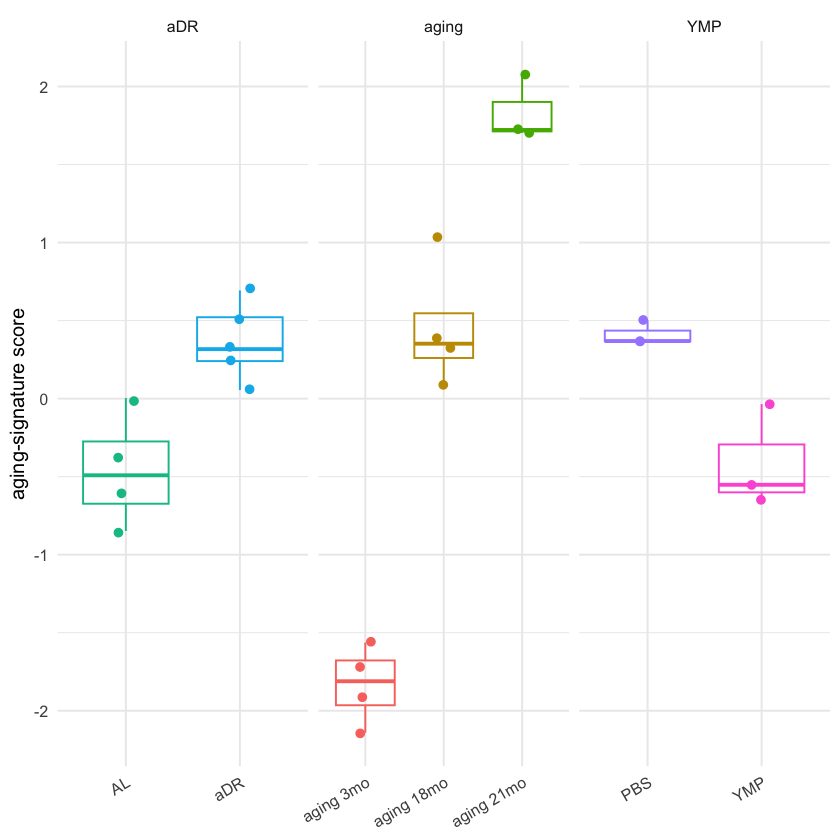

In [6]:
# score per mouse, by group (method SHOW)
scores <- lapply(names(fits), \(m) lapply(fits[[m]]$dds, signature_score, up = sig[[m]]$up, down = sig[[m]]$down)) %>% setNames(names(fits))
score_plot(scores[[SHOW]])

In [7]:
# treated minus control (diff) with a Welch t-test, per method
score_tests <- bind_rows(lapply(names(scores), \(m) bind_rows(score_test(scores[[m]]$aDR, 'aDR', 'AL'), score_test(scores[[m]]$YMP, 'YMP', 'PBS')) %>% mutate(method = m))) %>% relocate(method)
score_tests

method,treated,control,n_t,n_c,diff,t_test_p
<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>
kallisto,aDR,AL,5,4,0.726,0.0160
kallisto,YMP,PBS,3,3,-0.789,0.0035
RSEM,aDR,AL,5,4,0.822,0.0110
RSEM,YMP,PBS,3,3,-0.824,0.0430


`diff` < 0 = treated mice lower than control (rejuvenating direction); with 3–5 mice per group the p-values are rough.

## 5 · Pathways (GSEA)
**GSEA** (fgsea) ranks all genes by the Wald statistic and tests whether a gene set sits mainly at the top (up) or bottom (down); **NES** = score (positive = up). Sets: MSigDB's 50 **Hallmark** and ~7,500 **GO biological-process** sets.

In [8]:
# GSEA for aging, aDR and YMP with both gene-set collections, for each method; counts of significant sets
sets <- msigdb_sets()
contrasts <- c('aging_21v3', 'aDR', 'YMP')
gs_h <- lapply(fits, \(f) lapply(f$res[contrasts], run_gsea, sets = sets$hallmark))
gs_go <- lapply(fits, \(f) lapply(f$res[contrasts], run_gsea, sets = sets$gobp))
bind_rows(lapply(names(gs_h), \(m) bind_rows(lapply(names(gs_h[[m]]), \(n) tibble(method = m, contrast = n, hallmark_sig = sum(gs_h[[m]][[n]]$padj < 0.05), gobp_sig = sum(gs_go[[m]][[n]]$padj < 0.05))))))

method,contrast,hallmark_sig,gobp_sig
<chr>,<chr>,<int>,<int>
kallisto,aging_21v3,19,469
kallisto,aDR,23,471
kallisto,YMP,26,207
RSEM,aging_21v3,17,375
RSEM,aDR,17,539
RSEM,YMP,24,208


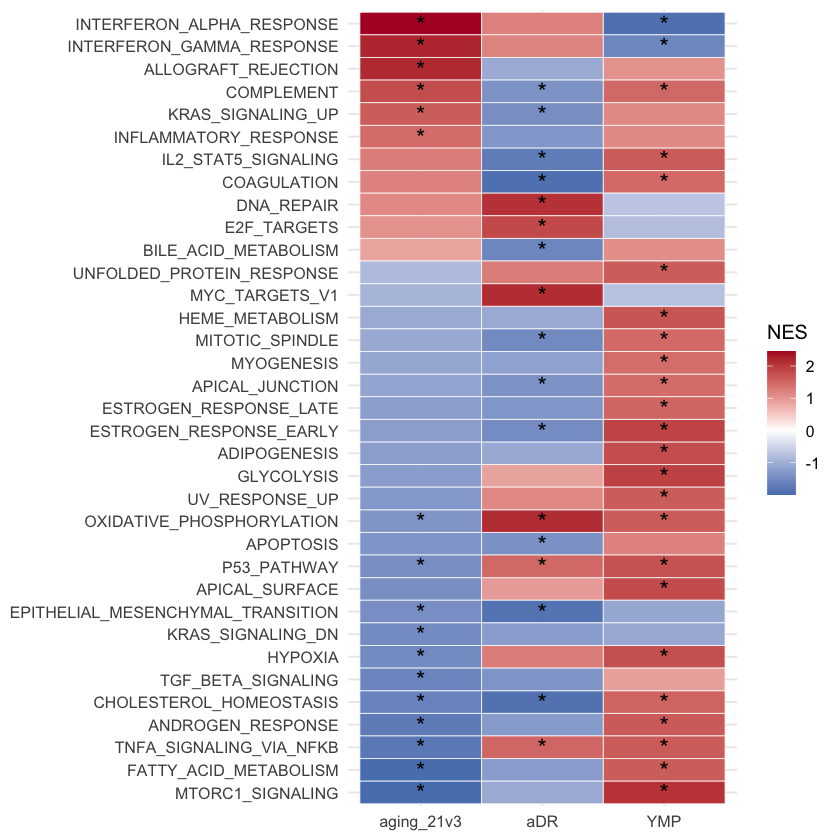

In [9]:
# Hallmark NES for aging vs the treatments (blue = down, red = up, * = padj < 0.05); opposite colours = reversal
nes_tiles(gs_h[[SHOW]])

In [10]:
# of the sets significant in aging: how many does each treatment reverse (opposite NES) or mimic (same sign), both padj < 0.05
bind_rows(Hallmark = bind_rows(lapply(gs_h, gsea_concordance), .id = 'method'), GO_BP = bind_rows(lapply(gs_go, gsea_concordance), .id = 'method'), .id = 'collection')

collection,method,intervention,aging_sets,significant_in_both,reversed,same_direction,NES_spearman_all_sets
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>
Hallmark,kallisto,aDR,19,8,5,3,0.06
Hallmark,kallisto,YMP,19,14,11,3,-0.35
Hallmark,RSEM,aDR,17,7,5,2,0.07
Hallmark,RSEM,YMP,17,11,10,1,-0.47
GO_BP,kallisto,aDR,464,66,26,40,0.11
GO_BP,kallisto,YMP,466,44,35,9,-0.24
GO_BP,RSEM,aDR,375,48,24,24,0.13
GO_BP,RSEM,YMP,375,31,28,3,-0.22


## 6 · The paper's named gene sets in our cerebellum data
**Aging (CAS, Fig. 2B):** the 26 genes named in the figure; the full 82-gene list is in the paper's Table S1, which we do not have. **aDR (Fig. 6J):** the 23 genes the paper reports as aDR-regulated in at least 4 brain regions (circadian and cycling genes).

In [11]:
# the paper's aging genes: log2FC and padj in aging, aDR and YMP
cas <- c('Gpr17','Hsph1','Dnajb1','Chordc1','P4ha1','Ahsa1','Hist3h2a','C4b','H2-Q6','H2-Q7','Cirbp','Flt1','Tipin','Ctsz','Pcdhb14','Abca8a','Pcdhb8','Pcdhb6','Pcdhb9','H2-K1','Psmb8','Hvcn1','C1qa','Ctss','Tyrobp','Trem2')
adr23 <- c('Chordc1','Cxcl12','Fabp7','Kdr','Adipor2','Gjb6','Mertk','Cry1','Klf15','Dbp','Usp2','Etnppl','Ciart','Sult1a1','Zbtb16','Fkbp5','Sgk1','Tsc22d3','Cirbp','Rbm3','Plin4','Fmo2','Hif3a')
gene_table(fits[[SHOW]]$res, cas) %>% arrange(padj_aging)

symbol,lfc_aging,padj_aging,lfc_aDR,padj_aDR,lfc_YMP,padj_YMP
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
C4b,1.88,2.2e-12,-0.41,0.8000,0.42,0.970
H2-K1,1.02,1.0e-08,-0.42,0.3300,-0.02,1.000
Ctss,1.00,1.8e-07,-0.14,0.8400,0.26,0.920
C1qa,1.09,3.7e-05,-0.11,0.9200,-0.01,1.000
Hsph1,-0.61,5.2e-05,-0.13,0.7800,0.52,0.046
H2-Q6,2.35,7.1e-05,-0.54,0.6200,0.51,0.820
Ctsz,0.60,1.0e-04,-0.14,0.7200,-0.02,1.000
Tyrobp,1.14,1.8e-04,-0.09,0.9500,-0.35,0.920
Psmb8,1.34,3.4e-04,0.23,0.8600,-0.15,0.990


In [12]:
# the paper's aDR genes: how many go up with aDR in our data, and how many are significant
bind_rows(lapply(fits, \(f) { t <- gene_table(f$res, adr23); tibble(genes = nrow(t), up_in_aDR = sum(t$lfc_aDR > 0), significant_aDR = sum(t$padj_aDR < 0.05, na.rm = TRUE)) }), .id = 'method')

method,genes,up_in_aDR,significant_aDR
<chr>,<int>,<int>,<int>
kallisto,23,19,11
RSEM,23,19,10


## 7 · Genes shared with aging, and biological themes
- Treatment DEGs that are also aging DEGs (21 vs 3 months), with their direction.
- The themes below use the annotated DEGs of notebook 03 (`results/de/RSEM/deg_annotation.csv`) and the pathways of section 5.

In [13]:
# treatment DEGs that are also aging DEGs: log2FC in aging and in the treatment; reversal = opposite sign
shared_with_aging(fits[[SHOW]]$res)

treatment,symbol,lfc_aging,lfc_treatment,vs_aging
<chr>,<chr>,<dbl>,<dbl>,<chr>
aDR,Fam163b,1.79,0.59,same
aDR,Ugt8a,-0.85,-0.95,same
aDR,Gjc2,-0.76,-0.99,same
aDR,Enpp6,-1.00,-0.77,same
aDR,Tmem278,-0.65,-0.87,same
YMP,Hsph1,-0.61,0.52,reversal
YMP,Parp4,0.83,-0.85,reversal


### Biological themes (RSEM)
**Established** = gene function from the annotation (org.Mm.eg.db names; GO biological-process sets in MSigDB) or, where marked *(literature)*, from published work not checked here. **Interpretation** = our reading; not tested.

**Aging (21 vs 3 months; 18 vs 3 is similar).**
*Established:* the up genes include complement (C4b, C1qa/b/c, Serping1), MHC class I antigen presentation (H2-D1, H2-Q7, B2m, Psmb8, Erap1) and inflammatory / microglial activation genes (Trem2, Tyrobp, Cd68, Clec7a, Cst7, Ccl3); the down genes include oligodendrocyte / myelin genes (Sox10, Gpr17, Ugt8a, Pllp; by name also Mog, Mal, Cldn11). Hallmark: interferon α / γ, allograft rejection and complement up; mTORC1, fatty-acid and cholesterol metabolism down.
*Interpretation:* aging brings microglial activation and innate-immune / interferon signalling and a weaker oligodendrocyte / myelin programme, in line with the paper's finding that white matter is especially vulnerable.

**aDR vs AL.**
*Established:* clock genes go up (Per1, Cry1, Cry2, Dbp, Ciart: GO circadian rhythm), as do the cold-inducible RNA-binding proteins Cirbp (GO response to cold) and Rbm3 *(literature)*; oligodendrocyte genes (Olig2, Ugt8a, Gjc2, Enpp6) and vascular genes (Kdr, Flt1, Cldn5, Eng: GO blood-vessel morphogenesis) go down. Hallmark: oxidative phosphorylation, MYC targets and DNA repair up; cholesterol homeostasis and EMT down. All 5 DEGs shared with aging (Ugt8a, Gjc2, Enpp6, Fam163b, Tmem278) move **like aging**.
*Interpretation:* restricted feeding shifts the circadian clock and likely raises glucocorticoid signalling (Tsc22d3, Zbtb16, Sult1a1 are known glucocorticoid-induced genes, *literature*), and may lower body temperature (Cirbp, Rbm3). It does not rescue, and may deepen, the age-related loss of oligodendrocyte genes. The clock genes also depend on when mice were sampled relative to feeding, which we do not know.

**YMP vs PBS.**
*Established:* the strongest change is Ptgds down (prostaglandin D2 synthase); extracellular-matrix and transporter genes (Ogn, Fmod, Mgp, Ccn3, Slc47a1, Slc6a13, Slc13a4) and Ccl21 also go down, while neurofilament genes (Nefl, Nefm, Nefh: GO axon development) go up. Hallmark: interferon α / γ down, the opposite of aging; mTORC1, glycolysis, oxidative phosphorylation, cholesterol and fatty-acid metabolism up. Both DEGs shared with aging are reversed (Parp4 down, Hsph1 up).
*Interpretation:* Ptgds and several of these down genes are typical markers of the meninges / fibroblasts *(literature)*, so their joint drop may reflect less meningeal tissue in the YMP samples rather than an effect of plasma. The pathway-level reversal of interferon signalling, the main aging signal, is the stronger evidence for rejuvenation, though with 3 vs 3 mice it remains indicative.

## 8 · Save
Small summary tables for the report.

In [14]:
# writes results/aging_vs_rejuvenation/*.csv
dir.create(file.path(ROOT, 'results/aging_vs_rejuvenation'), showWarnings = FALSE)
out <- file.path(ROOT, 'results/aging_vs_rejuvenation')
write_csv(ov, file.path(out, 'overlap_with_aging.csv')); write_csv(score_tests, file.path(out, 'signature_score_tests.csv'))
write_csv(bind_rows(lapply(gs_h, \(g) bind_rows(g, .id = 'contrast')), .id = 'method'), file.path(out, 'gsea_hallmark.csv'))
write_csv(bind_rows(Hallmark = bind_rows(lapply(gs_h, gsea_concordance), .id = 'method'), GO_BP = bind_rows(lapply(gs_go, gsea_concordance), .id = 'method'), .id = 'collection'), file.path(out, 'gsea_concordance.csv'))
write_csv(gene_table(fits[[SHOW]]$res, cas), file.path(out, 'paper_CAS_named_genes.csv'))
list.files(out)

[1] "gsea_concordance.csv"      "gsea_hallmark.csv"        
[3] "overlap_with_aging.csv"    "paper_CAS_named_genes.csv"
[5] "signature_score_tests.csv"